# CSE428 Lab Project — Evaluation-Only Notebook

**Purpose:** load the model weights that were already trained in the main notebook and run inference/evaluation **without retraining**.

This notebook intentionally contains:
- model architecture definitions (required so PyTorch can reconstruct the models),
- checkpoint loading with `torch.load(...)` + `load_state_dict(...)`,
- preprocessing using the **training mean/std stored in the checkpoint**,
- inference on new images,
- optional full test-set evaluation when labels/masks are provided.

It intentionally contains **no optimizer, no `loss.backward()`, no `optimizer.step()`, and no training loop**.


In [1]:
# 1. Imports and device
from pathlib import Path
import os
import tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


Device: cuda


## 2. Upload the saved weights

Upload the two files produced by the **main training notebook**.  
Supported common names include:

- Base U-Net: `base_unet_weights.pth` or `unet_best.pt`
- Attention U-Net: `attention_unet_weights.pth` or `attention_unet_best.pt`

The code also auto-detects similarly named `.pt` / `.pth` files.


In [2]:
# 2. Upload BOTH trained checkpoints
from google.colab import files

uploaded_weights = files.upload()
uploaded_weight_names = [
    name for name in uploaded_weights
    if name.lower().endswith(('.pt', '.pth'))
]

if len(uploaded_weight_names) < 2:
    raise ValueError(
        'Please upload BOTH trained checkpoint files (.pt/.pth): '
        'one Base U-Net and one Attention U-Net.'
    )

def find_checkpoint(names, role):
    lower_map = {name.lower(): name for name in names}

    if role == 'base':
        exact = ['base_unet_weights.pth', 'unet_best.pt', 'base_unet_best.pt']
        for candidate in exact:
            if candidate in lower_map:
                return Path('/content') / lower_map[candidate]

        candidates = [
            name for name in names
            if 'attention' not in name.lower()
            and ('unet' in name.lower() or 'base' in name.lower())
        ]
    else:
        exact = ['attention_unet_weights.pth', 'attention_unet_best.pt']
        for candidate in exact:
            if candidate in lower_map:
                return Path('/content') / lower_map[candidate]

        candidates = [name for name in names if 'attention' in name.lower()]

    if len(candidates) == 1:
        return Path('/content') / candidates[0]

    raise ValueError(
        f'Could not uniquely identify the {role} checkpoint. '
        f'Uploaded weight files: {names}'
    )

BASE_CHECKPOINT_PATH = find_checkpoint(uploaded_weight_names, 'base')
ATTENTION_CHECKPOINT_PATH = find_checkpoint(uploaded_weight_names, 'attention')

print('Base checkpoint     :', BASE_CHECKPOINT_PATH)
print('Attention checkpoint:', ATTENTION_CHECKPOINT_PATH)


Saving attention_unet_weights.pth to attention_unet_weights.pth
Saving base_unet_weights.pth to base_unet_weights.pth
Base checkpoint     : /content/base_unet_weights.pth
Attention checkpoint: /content/attention_unet_weights.pth


## 3. Load checkpoint files (still no training)

The checkpoint should contain the saved component weights for:
`encoder`, `bottleneck`, `decoder`, and `classifier`.

The loader also accepts a flat state dictionary if its keys are prefixed with those component names.


In [3]:
# 3. Read checkpoints and metadata
def torch_load_checkpoint(path):
    # PyTorch 2.6+ defaults can reject checkpoints containing NumPy metadata.
    try:
        return torch.load(path, map_location='cpu', weights_only=False)
    except TypeError:
        return torch.load(path, map_location='cpu')

def unpack_checkpoint(raw_checkpoint):
    if not isinstance(raw_checkpoint, dict):
        raise TypeError('Checkpoint must be a dictionary.')

    required = {'encoder', 'bottleneck', 'decoder', 'classifier'}
    if required.issubset(raw_checkpoint.keys()):
        return raw_checkpoint

    # Optional compatibility with a flat/prefixed state_dict.
    flat = raw_checkpoint.get('model_state_dict', raw_checkpoint.get('state_dict'))
    if isinstance(flat, dict):
        rebuilt = {}
        for component in required:
            prefix = component + '.'
            sub = {
                key[len(prefix):]: value
                for key, value in flat.items()
                if key.startswith(prefix)
            }
            if sub:
                rebuilt[component] = sub

        if required.issubset(rebuilt.keys()):
            # Preserve any useful metadata from the outer checkpoint.
            for key in ['num_classes', 'class_names', 'class_species', 'train_mean', 'train_std']:
                if key in raw_checkpoint:
                    rebuilt[key] = raw_checkpoint[key]
            return rebuilt

    raise KeyError(
        'Checkpoint format is not compatible. Expected saved keys: '
        "'encoder', 'bottleneck', 'decoder', and 'classifier'."
    )

base_checkpoint = unpack_checkpoint(torch_load_checkpoint(BASE_CHECKPOINT_PATH))
attention_checkpoint = unpack_checkpoint(torch_load_checkpoint(ATTENTION_CHECKPOINT_PATH))

def infer_num_classes(checkpoint):
    if 'num_classes' in checkpoint:
        return int(checkpoint['num_classes'])

    classifier_state = checkpoint['classifier']
    # This matches the Classifier used in the main notebook.
    if 'layer3.weight' in classifier_state:
        return int(classifier_state['layer3.weight'].shape[0])

    raise KeyError('Could not infer num_classes from the checkpoint.')

NUM_CLASSES = infer_num_classes(base_checkpoint)
if infer_num_classes(attention_checkpoint) != NUM_CLASSES:
    raise ValueError('The two checkpoints use different numbers of classes.')

class_names = base_checkpoint.get(
    'class_names', [f'Class {i}' for i in range(NUM_CLASSES)]
)
class_species = base_checkpoint.get(
    'class_species', ['Unknown' for _ in range(NUM_CLASSES)]
)

if 'train_mean' not in base_checkpoint or 'train_std' not in base_checkpoint:
    raise KeyError(
        "The Base checkpoint does not contain 'train_mean' and 'train_std'. "
        'Use the checkpoint saved by the main notebook, because evaluation must '
        'use the SAME normalization as training.'
    )

train_mean = np.asarray(base_checkpoint['train_mean'], dtype=np.float32).reshape(1, 3, 1, 1)
train_std = np.asarray(base_checkpoint['train_std'], dtype=np.float32).reshape(1, 3, 1, 1)

print('Number of classes:', NUM_CLASSES)
print('Training mean:', train_mean.reshape(-1))
print('Training std :', train_std.reshape(-1))
print('Checkpoint metadata loaded successfully.')


Number of classes: 37
Training mean: [0.4785378  0.44590273 0.39542103]
Training std : [0.2616738  0.25640446 0.26431084]
Checkpoint metadata loaded successfully.


## 4. Model architecture

These definitions must match the training notebook exactly. Defining the architecture is **not retraining**; it only creates the network structure so the saved parameters can be loaded.


In [4]:
# 4. Exact architecture used by the trained models
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding='same'),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding='same'),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)


class UNetEncoder(nn.Module):
    def __init__(self, in_channels=3, first_out_channel=16):
        super().__init__()
        c = first_out_channel
        self.enc1 = ConvBlock(in_channels, c)
        self.enc2 = ConvBlock(c, c * 2)
        self.enc3 = ConvBlock(c * 2, c * 4)
        self.enc4 = ConvBlock(c * 4, c * 8)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x1 = self.enc1(x)
        x2 = self.enc2(self.pool(x1))
        x3 = self.enc3(self.pool(x2))
        x4 = self.enc4(self.pool(x3))
        return x1, x2, x3, x4


class UNetBottleneck(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.enc = ConvBlock(in_channels, in_channels * 2)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        return self.enc(self.pool(x))


class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = nn.Sequential(
            nn.Conv2d(2 * out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU()
        )

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)


class UNetDecoder(nn.Module):
    def __init__(self, in_channels=256):
        super().__init__()
        self.decode1 = DecoderBlock(in_channels, in_channels // 2)
        self.decode2 = DecoderBlock(in_channels // 2, in_channels // 4)
        self.decode3 = DecoderBlock(in_channels // 4, in_channels // 8)
        self.decode4 = DecoderBlock(in_channels // 8, in_channels // 16)
        self.final_conv = nn.Conv2d(in_channels // 16, 1, kernel_size=1)

    def forward(self, x5, x4, x3, x2, x1):
        x = self.decode1(x5, x4)
        x = self.decode2(x, x3)
        x = self.decode3(x, x2)
        x = self.decode4(x, x1)
        return self.final_conv(x).squeeze(1)


class Classifier(nn.Module):
    # Corrected syntax: the uploaded notebook had a non-default argument
    # after a default argument, which causes a SyntaxError.
    def __init__(self, num_classes, in_channels=128):
        super().__init__()
        self.layer1 = nn.Linear(in_channels * 4 * 4, 512)
        self.layer2 = nn.Linear(512, 128)
        self.layer3 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = F.adaptive_avg_pool2d(x, (4, 4))
        x = x.view(x.shape[0], -1)
        x = F.relu(self.layer1(x))
        x = F.relu(self.layer2(x))
        return self.layer3(x)


class AttentionGate(nn.Module):
    def __init__(self, skip_channels, gate_channels, inter_channels):
        super().__init__()
        self.skip_conv = nn.Conv2d(skip_channels, inter_channels, kernel_size=1)
        self.gate_conv = nn.Conv2d(gate_channels, inter_channels, kernel_size=1)
        self.attention_conv = nn.Conv2d(inter_channels, 1, kernel_size=1)

    def forward(self, skip, gate):
        attention = F.relu(self.skip_conv(skip) + self.gate_conv(gate))
        attention = torch.sigmoid(self.attention_conv(attention))
        return skip * attention


class AttentionDecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.attention = AttentionGate(
            skip_channels=out_channels,
            gate_channels=out_channels,
            inter_channels=max(out_channels // 2, 1)
        )
        self.conv = nn.Sequential(
            nn.Conv2d(2 * out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU()
        )

    def forward(self, x, skip):
        x = self.up(x)
        attended_skip = self.attention(skip, x)
        x = torch.cat([attended_skip, x], dim=1)
        return self.conv(x)


class AttentionUNetDecoder(nn.Module):
    def __init__(self, in_channels=256):
        super().__init__()
        self.decode1 = AttentionDecoderBlock(in_channels, in_channels // 2)
        self.decode2 = AttentionDecoderBlock(in_channels // 2, in_channels // 4)
        self.decode3 = AttentionDecoderBlock(in_channels // 4, in_channels // 8)
        self.decode4 = AttentionDecoderBlock(in_channels // 8, in_channels // 16)
        self.final_conv = nn.Conv2d(in_channels // 16, 1, kernel_size=1)

    def forward(self, x5, x4, x3, x2, x1):
        x = self.decode1(x5, x4)
        x = self.decode2(x, x3)
        x = self.decode3(x, x2)
        x = self.decode4(x, x1)
        return self.final_conv(x).squeeze(1)


## 5. Reconstruct models and load the trained weights

After this cell, every module is switched to evaluation mode and all parameters are frozen.


In [5]:
# 5. Instantiate + LOAD saved weights (no optimizer, no backpropagation)
def build_model(attention=False):
    encoder = UNetEncoder(in_channels=3, first_out_channel=16).to(device)
    bottleneck = UNetBottleneck(in_channels=128).to(device)
    decoder = (
        AttentionUNetDecoder(in_channels=256).to(device)
        if attention
        else UNetDecoder(in_channels=256).to(device)
    )
    classifier = Classifier(num_classes=NUM_CLASSES, in_channels=128).to(device)
    return encoder, bottleneck, decoder, classifier

def load_components(checkpoint, model_parts):
    encoder, bottleneck, decoder, classifier = model_parts
    encoder.load_state_dict(checkpoint['encoder'], strict=True)
    bottleneck.load_state_dict(checkpoint['bottleneck'], strict=True)
    decoder.load_state_dict(checkpoint['decoder'], strict=True)
    classifier.load_state_dict(checkpoint['classifier'], strict=True)

    for module in model_parts:
        module.eval()
        for parameter in module.parameters():
            parameter.requires_grad_(False)

    return model_parts

base_model = load_components(base_checkpoint, build_model(attention=False))
attention_model = load_components(attention_checkpoint, build_model(attention=True))

print('✓ Base U-Net trained weights loaded.')
print('✓ Attention U-Net trained weights loaded.')
print('✓ All model parts are in eval() mode and frozen.')
print('✓ NO RETRAINING has occurred.')


✓ Base U-Net trained weights loaded.
✓ Attention U-Net trained weights loaded.
✓ All model parts are in eval() mode and frozen.
✓ NO RETRAINING has occurred.


## 6. Preprocessing and inference helpers

The new image is resized to `128×128`, converted to `[C,H,W]`, and normalized using the **saved training statistics**. This mirrors the original notebook's inference preprocessing.


In [6]:
# 6. Preprocessing + prediction
IMAGE_SIZE = (128, 128)

def prepare_image_array(image):
    if image.ndim == 2:
        image = np.stack([image, image, image], axis=-1)

    if image.shape[-1] == 4:
        image = image[:, :, :3]

    image = skimage.transform.resize(
        image, IMAGE_SIZE, anti_aliasing=True
    ).astype(np.float32)

    chw = np.transpose(image, (2, 0, 1))
    mean = train_mean.reshape(3, 1, 1)
    std = train_std.reshape(3, 1, 1)
    chw = (chw - mean) / (std + 1e-4)

    return image, chw.astype(np.float32)

@torch.inference_mode()
def predict_array(image, model_parts):
    encoder, bottleneck, decoder, classifier = model_parts
    display_image, chw = prepare_image_array(image)
    x = torch.from_numpy(chw).unsqueeze(0).to(device)

    x1, x2, x3, x4 = encoder(x)
    x5 = bottleneck(x4)
    mask_logits = decoder(x5, x4, x3, x2, x1)
    class_logits = classifier(x4)

    probability = torch.softmax(class_logits, dim=1)
    confidence, predicted_class = probability.max(dim=1)
    predicted_mask = (torch.sigmoid(mask_logits) > 0.5).float()

    return {
        'display_image': display_image,
        'predicted_mask': predicted_mask[0].cpu().numpy(),
        'class_id': int(predicted_class.item()),
        'confidence': float(confidence.item())
    }

def readable_class_name(class_id):
    if 0 <= class_id < len(class_names):
        name = class_names[class_id]
        species = class_species[class_id] if class_id < len(class_species) else 'Unknown'
        return f'{name} ({species})'
    return f'Class {class_id}'

def show_prediction(image, model_parts, model_name):
    result = predict_array(image, model_parts)

    print(f'{model_name}: {readable_class_name(result["class_id"])}')
    print(f'Classification confidence: {result["confidence"] * 100:.2f}%')

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(result['display_image'])
    plt.axis('off')
    plt.title('Input image')

    plt.subplot(1, 2, 2)
    plt.imshow(result['display_image'])
    plt.imshow(result['predicted_mask'], cmap='Reds', alpha=0.30)
    plt.axis('off')
    plt.title(model_name + ' predicted mask')

    plt.tight_layout()
    plt.show()

    return result


## 7. ON-SPOT DEMO — upload one or more new images

Use this when your faculty gives you **image files only**.  
Because an unlabeled image has no ground-truth class/mask, this section can show the prediction, mask and classification confidence, but it **cannot legitimately calculate IoU/Dice/accuracy** without ground truth.


Saving doggg.webp to doggg.webp

File: doggg.webp
Attention U-Net: Basset Hound (Dog)
Classification confidence: 98.82%


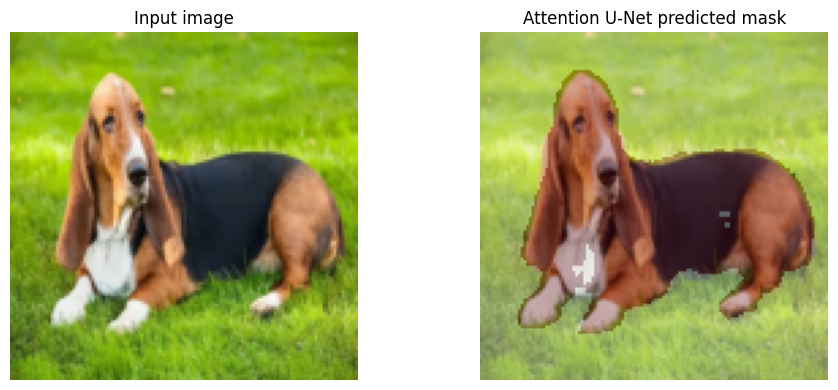

In [9]:
# 7. Upload faculty-provided image(s) and run inference immediately
from google.colab import files

uploaded_images = files.upload()
image_names = [
    name for name in uploaded_images
    if name.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))
]

if not image_names:
    raise ValueError('No supported image file was uploaded.')

MODEL_TO_DEMO = 'attention'   # change to 'base' if your faculty asks

selected_model = attention_model if MODEL_TO_DEMO == 'attention' else base_model
selected_model_name = 'Attention U-Net' if MODEL_TO_DEMO == 'attention' else 'Base U-Net'

for image_name in image_names:
    print('\nFile:', image_name)
    image = plt.imread('/content/' + image_name)
    show_prediction(image, selected_model, selected_model_name)
